# Biography databases

Scholarly biographical dictionaries Cultura can be compared with: one biography downloaded from each (`building_scripts/dictionary_texts.py`).

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "5-annotations" / "building_scripts"))
from dictionary_texts import DB, DICTIONARIES, OUT

sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

texts = json.loads(OUT.read_text(encoding="utf-8"))
downloaded = {key: row for key, row in texts.items() if "text" in row and "pid" in DICTIONARIES[key]}
treccani = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "treccani_validation" / "treccani_texts.parquet")
labels = pl.DataFrame(duckdb.connect(str(DB), read_only=True).execute(
    "SELECT entity.qid AS wikidata_id, entity.label_en AS label FROM individual WHERE entity.qid IN (SELECT unnest(?)) AND entity.label_en IS NOT NULL",
    [treccani["wikidata_id"].to_list()]).fetchall(), schema=["wikidata_id", "label"], orient="row")
treccani_example = treccani.join(labels, on="wikidata_id").sort("wikidata_id").sample(1, seed=42).row(0, named=True)
example_qids = [row["qid"] for row in downloaded.values()] + [treccani_example["wikidata_id"]]
ENRICHED_DB = ROOT / "data" / "cultura" / "cultura_enriched_v3.2.duckdb"


def year(value, source):
    return f"c. {value}" if source == "estimated" else str(value)


lifespans = {qid: f"({year(birth, birth_source)}–{year(death, death_source)})" for qid, birth, birth_source, death, death_source in duckdb.connect(str(ENRICHED_DB), read_only=True).execute(
    "SELECT entity.qid, birth_date.year, birth_date.source, death_date.year, death_date.source FROM individual_enriched WHERE entity.qid IN (SELECT unnest(?))",
    [example_qids]).fetchall()}
print(f"Treccani example: {treccani_example['label']} ({treccani_example['wikidata_id']}), {treccani_example['dbi_url']}")
print(f"{len(DICTIONARIES)} dictionaries, {len(downloaded)} with a downloaded biography and a Wikidata identifier")

Treccani example: Anselm, Duke of Friuli (Q569615), https://www.treccani.it/enciclopedia/anselmo-di-nonantola-santo_(Dizionario-Biografico)/
21 dictionaries, 12 with a downloaded biography and a Wikidata identifier


## Overview table

In [2]:
REGIONS = {
    "treccani": "Italy",
    "deutsche_biographie": "German-speaking world", "oebl": "Austria-Hungary", "dwb": "Wales", "sbl": "Sweden",
    "nbl": "Norway", "dbl": "Denmark", "dcb": "Canada", "iranica": "Persia, Islamic East", "encykorea": "Korea",
    "sep": "Global / Philosophers", "mactutor": "Global / Mathematicians", "catholic_encyclopedia": "Global / Catholic Church",
}

overview = pl.DataFrame([
    {
        "Dictionary": DICTIONARIES[key]["name"],
        "Region / Topic": REGIONS[key],
        "Biography Example": f'{row["label"]} {lifespans[row["qid"]]}',
        "Number of Characters": len(row["text"]),
    }
    for key, row in downloaded.items()
] + [{
    "Dictionary": "Dizionario Biografico degli Italiani (Treccani)",
    "Region / Topic": REGIONS["treccani"],
    "Biography Example": f'{treccani_example["label"]} {lifespans[treccani_example["wikidata_id"]]}',
    "Number of Characters": len(treccani_example["text"]),
}]).sort("Dictionary")
assert overview["Dictionary"].is_unique().all() and overview["Biography Example"].null_count() == 0
overview.shape

(13, 4)

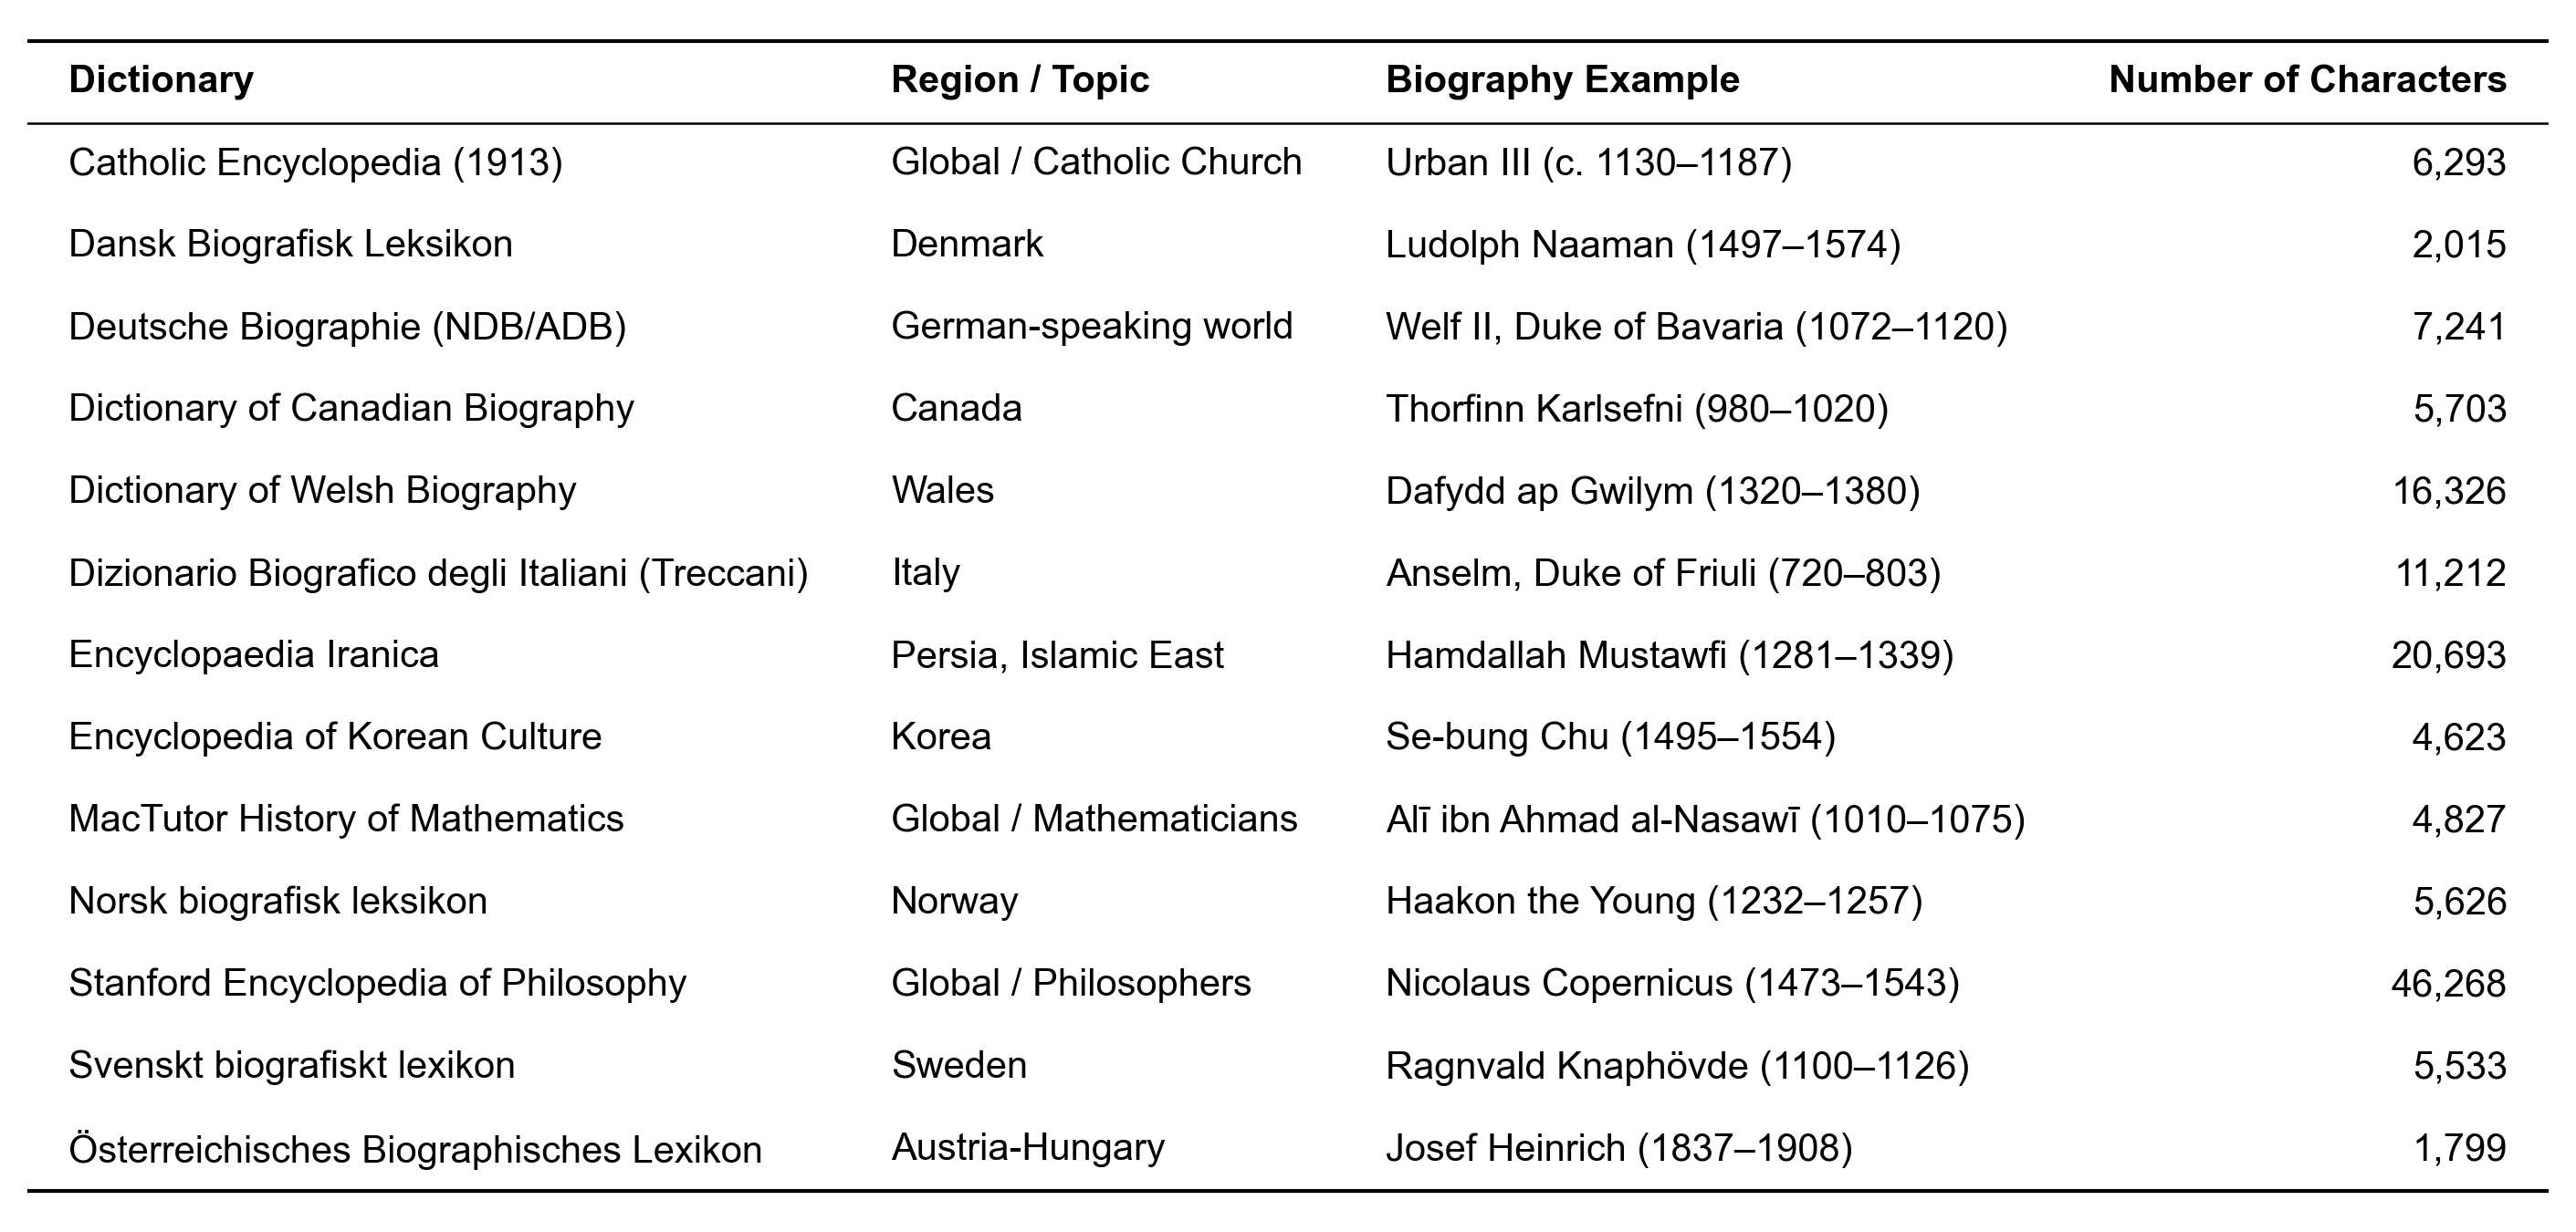

In [3]:
show_table(overview, font_size=10)

## Benchmark coverage

Cultura individuals covered by at least one dictionary, with an English label, a birth and a death year (`building_scripts/benchmark_population.py`). Region from the birthplace, else the country of citizenship, in present-day borders; century of birth.

In [4]:
population = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_population.parquet")
NAMES = {key: dictionary["name"] for key, dictionary in DICTIONARIES.items()} | {"treccani": "Dizionario Biografico degli Italiani (Treccani)"}
PERIODS = [(-10_000, 500, "before 500"), (500, 1000, "500–999"), (1000, 1300, "1000–1299"), (1300, 1500, "1300–1499"),
           (1500, 1600, "1500s"), (1600, 1700, "1600s"), (1700, 1800, "1700s"), (1800, 1900, "1800s"), (1900, 3000, "1900s")]
REGION_ORDER = ["Western Europe", "Northern Europe", "Southern Europe", "Eastern Europe", "Middle East & North Africa",
                "South & Central Asia", "East Asia", "Southeast Asia", "Sub-Saharan Africa", "North America",
                "Latin America", "Oceania", "Other", "Unknown"]

period = pl.lit(None, dtype=pl.Utf8)
for low, high, label in reversed(PERIODS):
    period = pl.when((pl.col("birth_year") >= low) & (pl.col("birth_year") < high)).then(pl.lit(label)).otherwise(period)
people = population.unique("qid").with_columns(period=period)
assert people["period"].null_count() == 0
print(f"{len(population):,} dictionary entries, {len(people):,} individuals")

114,763 dictionary entries, 109,452 individuals


### Individuals per dictionary

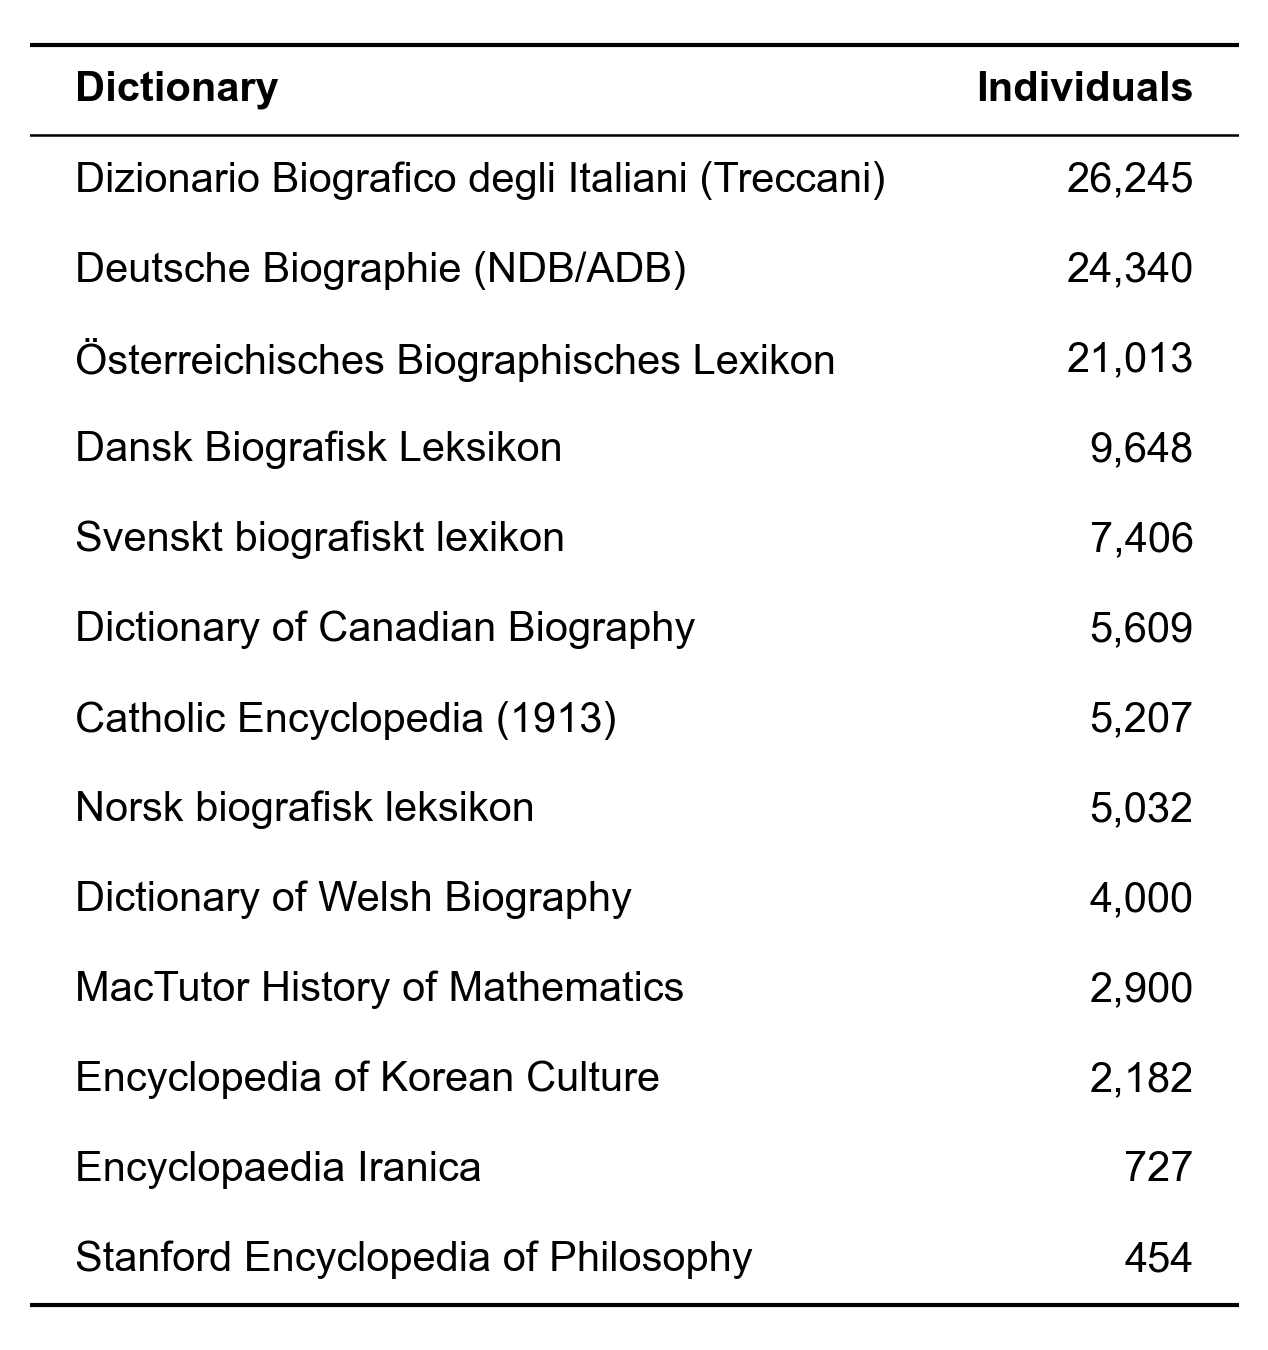

In [5]:
per_dictionary = (population.group_by("dictionary").agg(pl.col("qid").n_unique().alias("Individuals"))
    .with_columns(pl.col("dictionary").replace_strict(NAMES).alias("Dictionary"))
    .select("Dictionary", "Individuals").sort("Individuals", descending=True))
show_table(per_dictionary, font_size=10)

### Individuals per region and period of birth

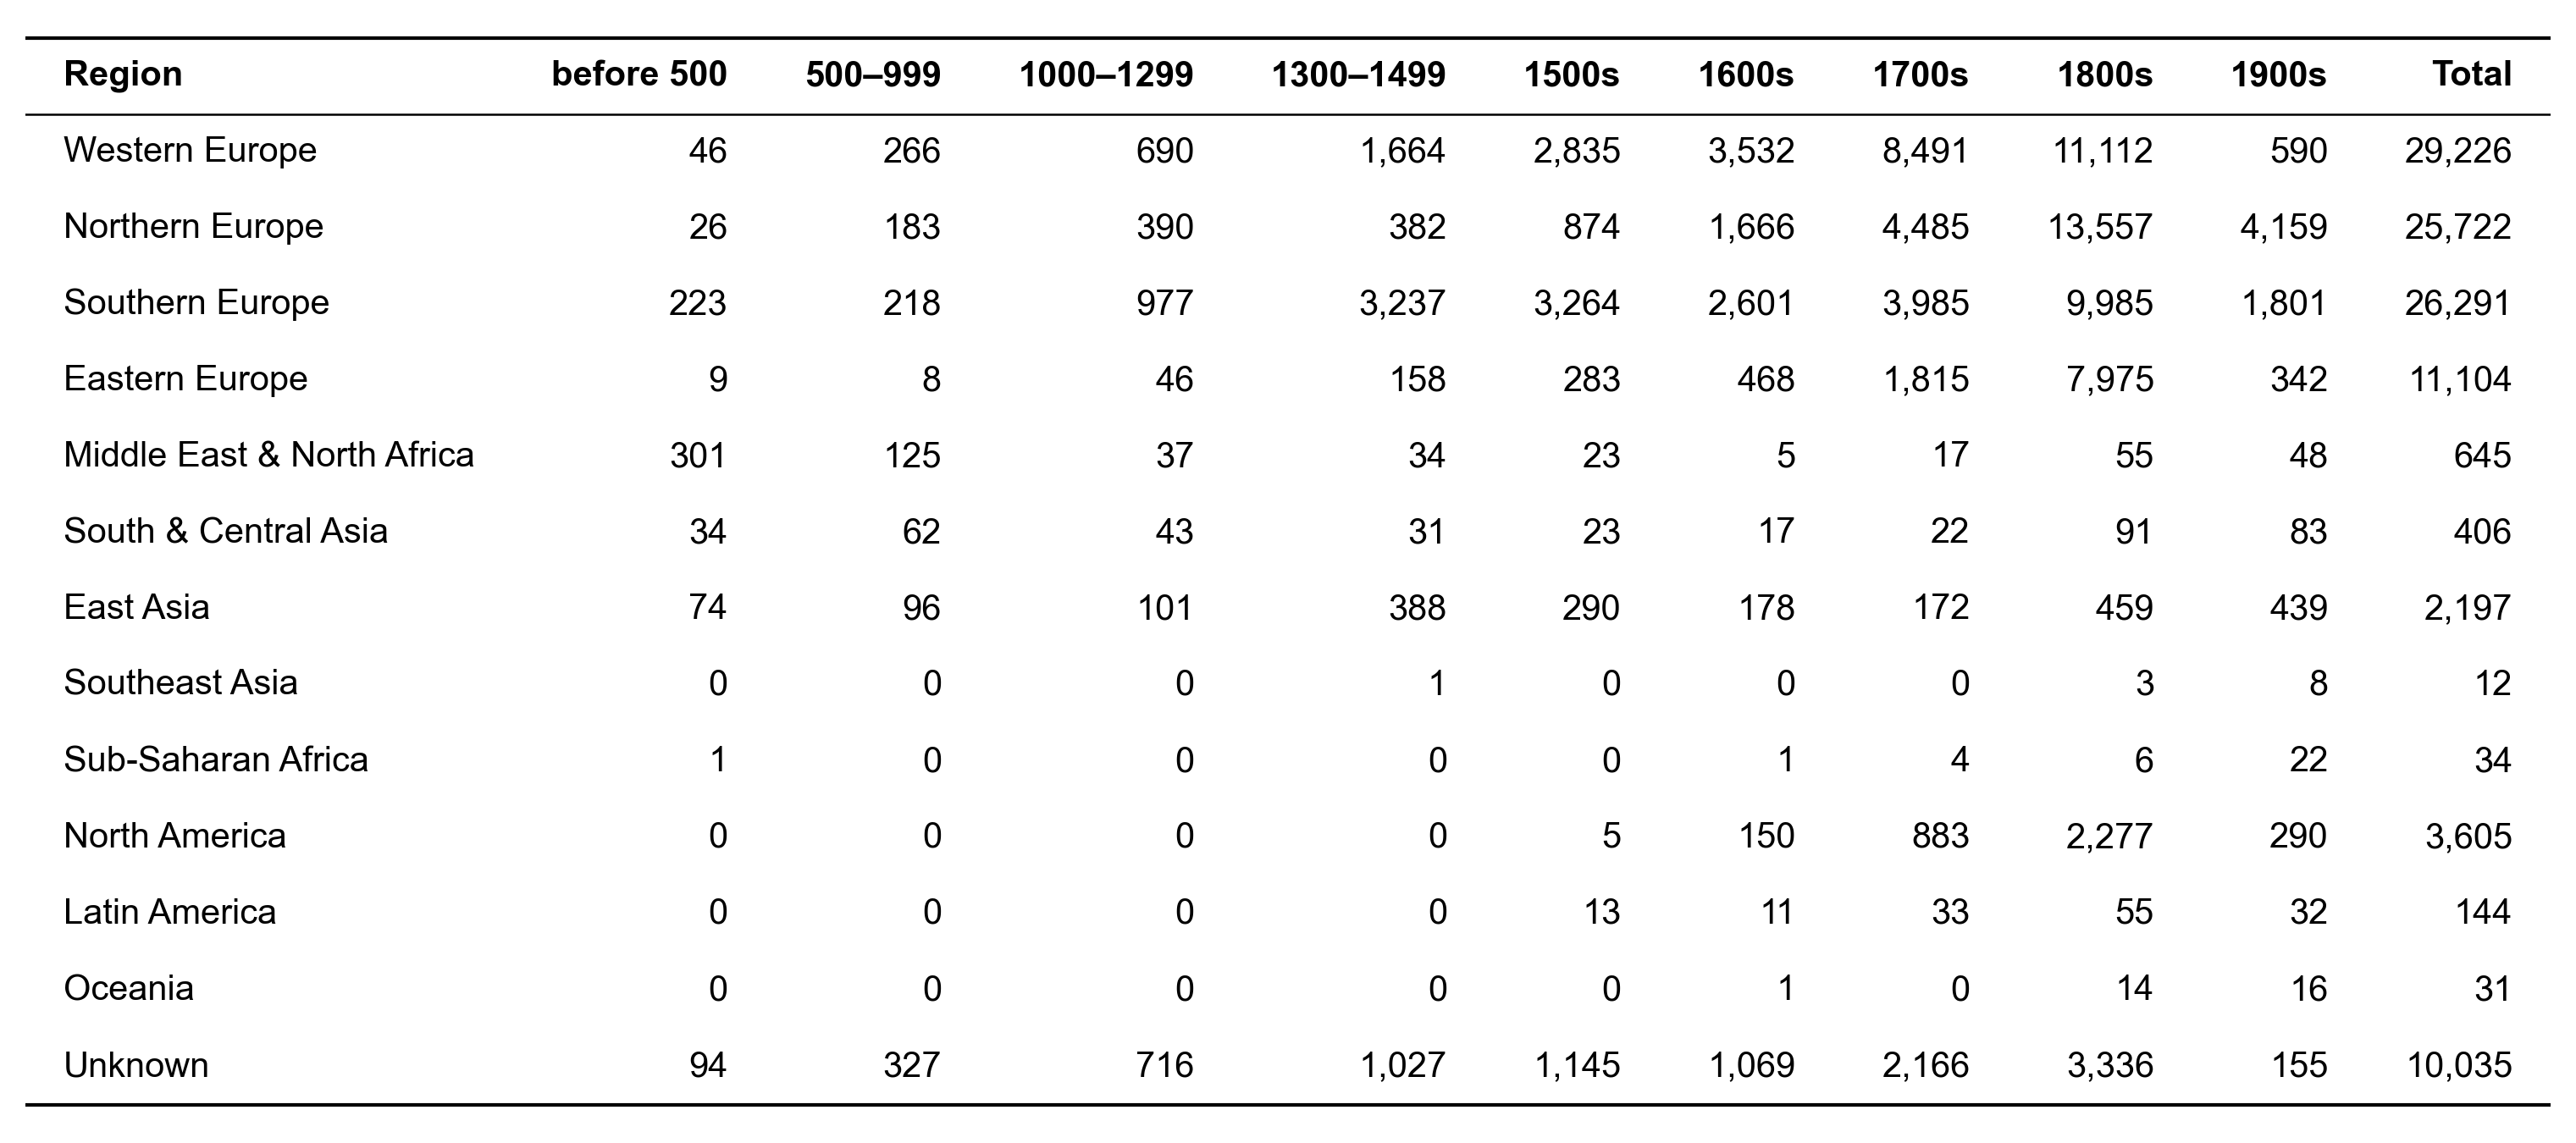

In [6]:
labels = [label for _, _, label in PERIODS]
per_region = (people.pivot(on="period", index="region", values="qid", aggregate_function="len")
    .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order"))
    .sort("order").fill_null(0))
per_region = per_region.select(pl.col("region").alias("Region"), *[pl.col(label) for label in labels if label in per_region.columns]).with_columns(
    Total=pl.sum_horizontal(*[pl.col(label) for label in labels if label in per_region.columns]))
show_table(per_region, font_size=10)

## Benchmark of 300 individuals

Drawn by `building_scripts/benchmark_sample.py`: a quota per region, spread over the periods of birth and the dictionaries of each region. Only individuals with the three Cultura life stages (early, active and late), each with its years, dated or estimated, enter the benchmark.

In [7]:
sample = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_sample.parquet")
benchmark = sample.filter(pl.col("in_benchmark"))
assert len(benchmark) == 300 and benchmark["qid"].is_unique().all()
SHORT = {"Western Europe": "W. Europe", "Northern Europe": "N. Europe", "Southern Europe": "S. Europe", "Eastern Europe": "E. Europe",
         "Middle East & North Africa": "MENA", "South & Central Asia": "S. & C. Asia", "East Asia": "E. Asia",
         "North America": "N. America", "Latin America": "Lat. America", "Sub-Saharan Africa": "SS Africa", "Oceania": "Oceania"}
regions = [region for region in REGION_ORDER if region in benchmark["region"].unique().to_list()]
benchmark.head()

dictionary,qid,dictionary_id,label,birth_year,death_year,latitude,longitude,located_by,country,region,century,period,rank,three_stages,in_benchmark
str,str,str,str,i64,i64,f64,f64,str,str,str,i64,str,i64,bool,bool
"""catholic_encyclopedia""","""Q169288""","""08018b""","""Innocent VI""",1282,1362,45.371389,1.403889,"""birthplace""","""France""","""Western Europe""",13,"""1000–1299""",0,true,true
"""sbl""","""Q61873""","""17601""","""Dorothea of Brandenburg""",1430,1495,52.414139,12.554083,"""birthplace""","""Germany""","""Western Europe""",15,"""1300–1499""",1,true,true
"""sep""","""Q190944""","""bodin""","""Jean Bodin""",1530,1596,47.472778,-0.555555,"""birthplace""","""France""","""Western Europe""",16,"""1500s""",2,true,true
"""dcb""","""Q3384708""","""denys_de_la_ronde_pierre_2""","""Pierre Denys de La Ronde""",1631,1708,47.392778,0.688333,"""birthplace""","""France""","""Western Europe""",17,"""1600s""",3,true,true
"""iranica""","""Q1378109""","""jaubert-pierre""","""Pierre Amédée Jaubert""",1779,1847,43.527778,5.445556,"""birthplace""","""France""","""Western Europe""",18,"""1700s""",4,true,true


### Benchmark individuals per dictionary and region

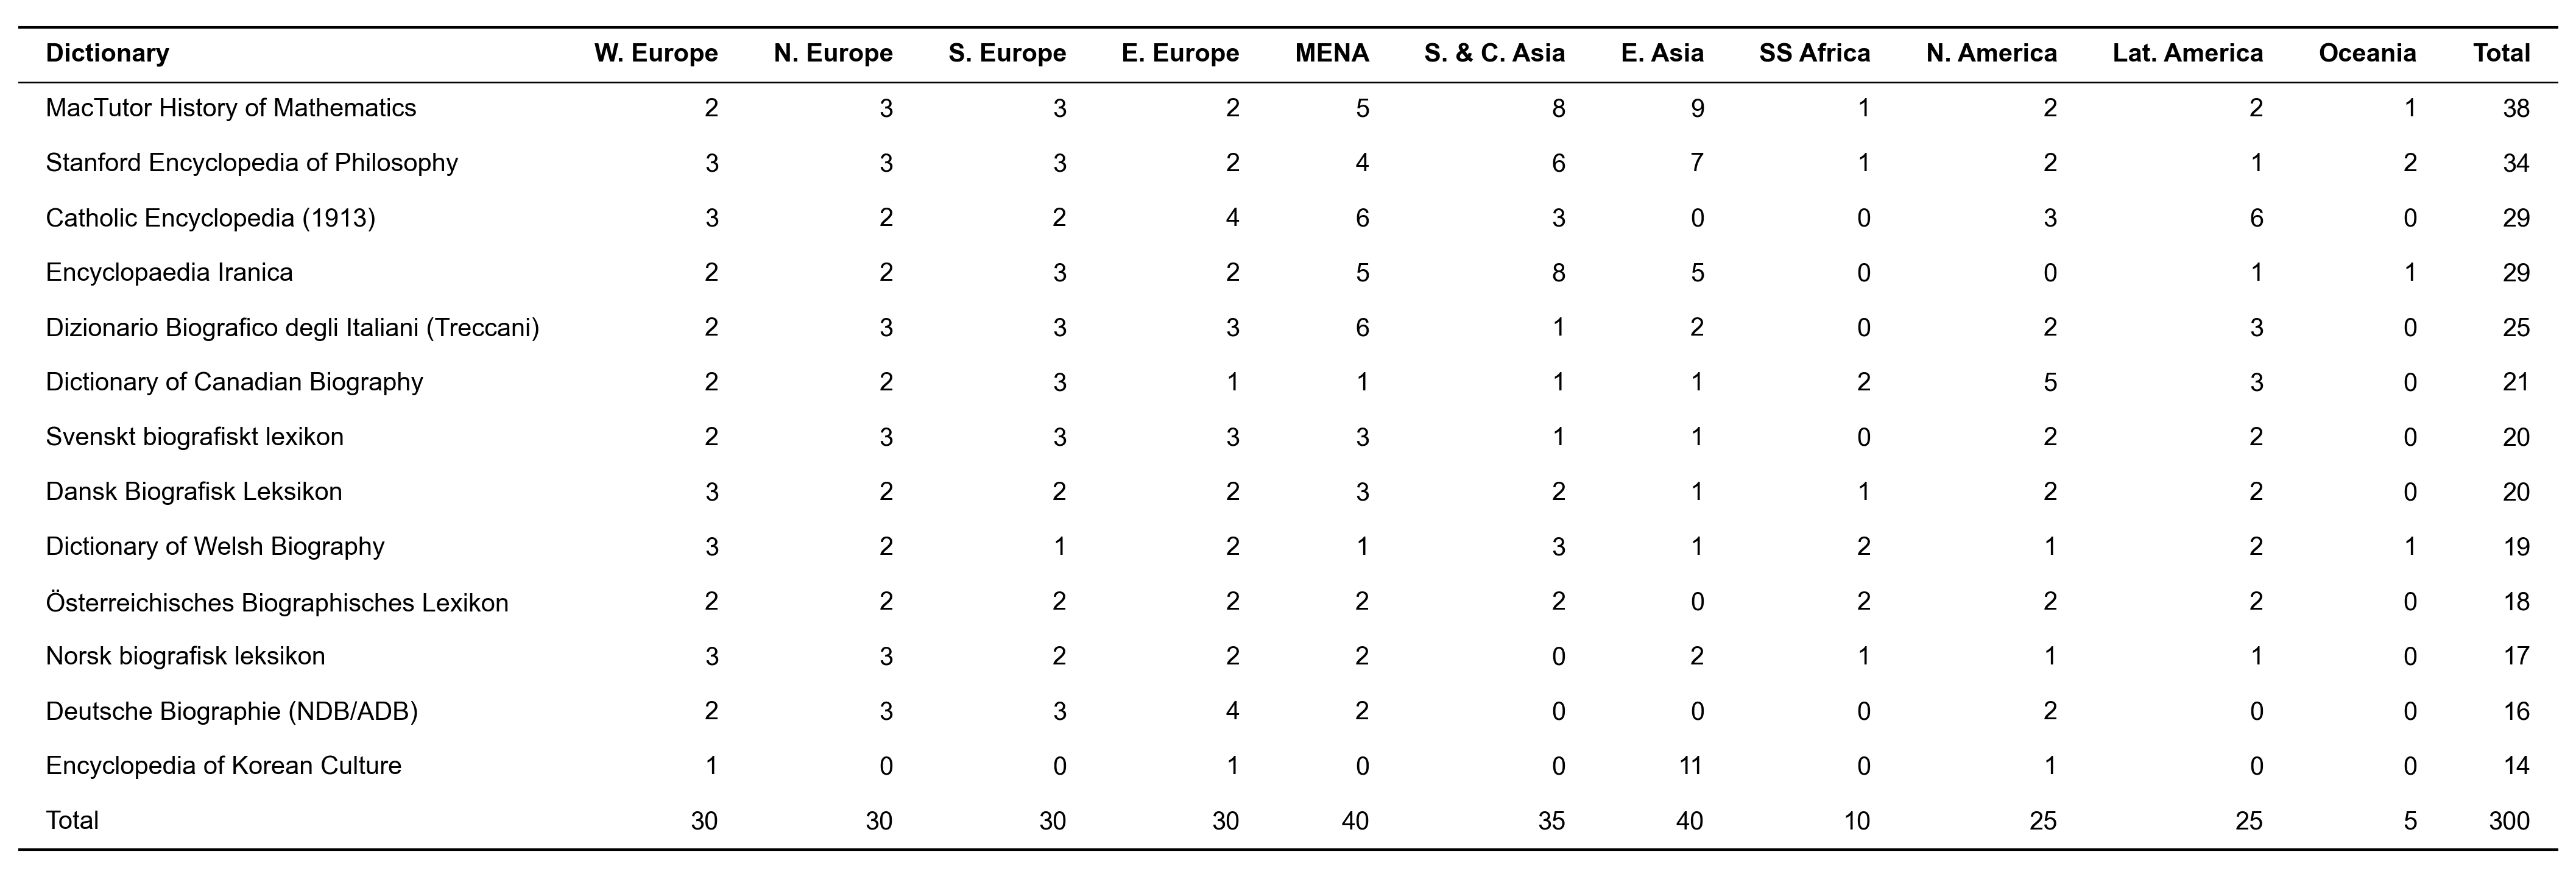

In [8]:
per_dictionary_region = (benchmark.pivot(on="region", index="dictionary", values="qid", aggregate_function="len").fill_null(0)
    .with_columns(pl.col("dictionary").replace_strict(NAMES).alias("Dictionary"))
    .select("Dictionary", *[pl.col(region).alias(SHORT[region]) for region in regions]))
per_dictionary_region = per_dictionary_region.with_columns(Total=pl.sum_horizontal(*[SHORT[region] for region in regions])).sort("Total", descending=True)
totals = pl.DataFrame([{"Dictionary": "Total", **{c: per_dictionary_region[c].sum() for c in per_dictionary_region.columns[1:]}}])
show_table(pl.concat([per_dictionary_region, totals], how="vertical_relaxed"), font_size=10)

### Benchmark individuals per region and period of birth

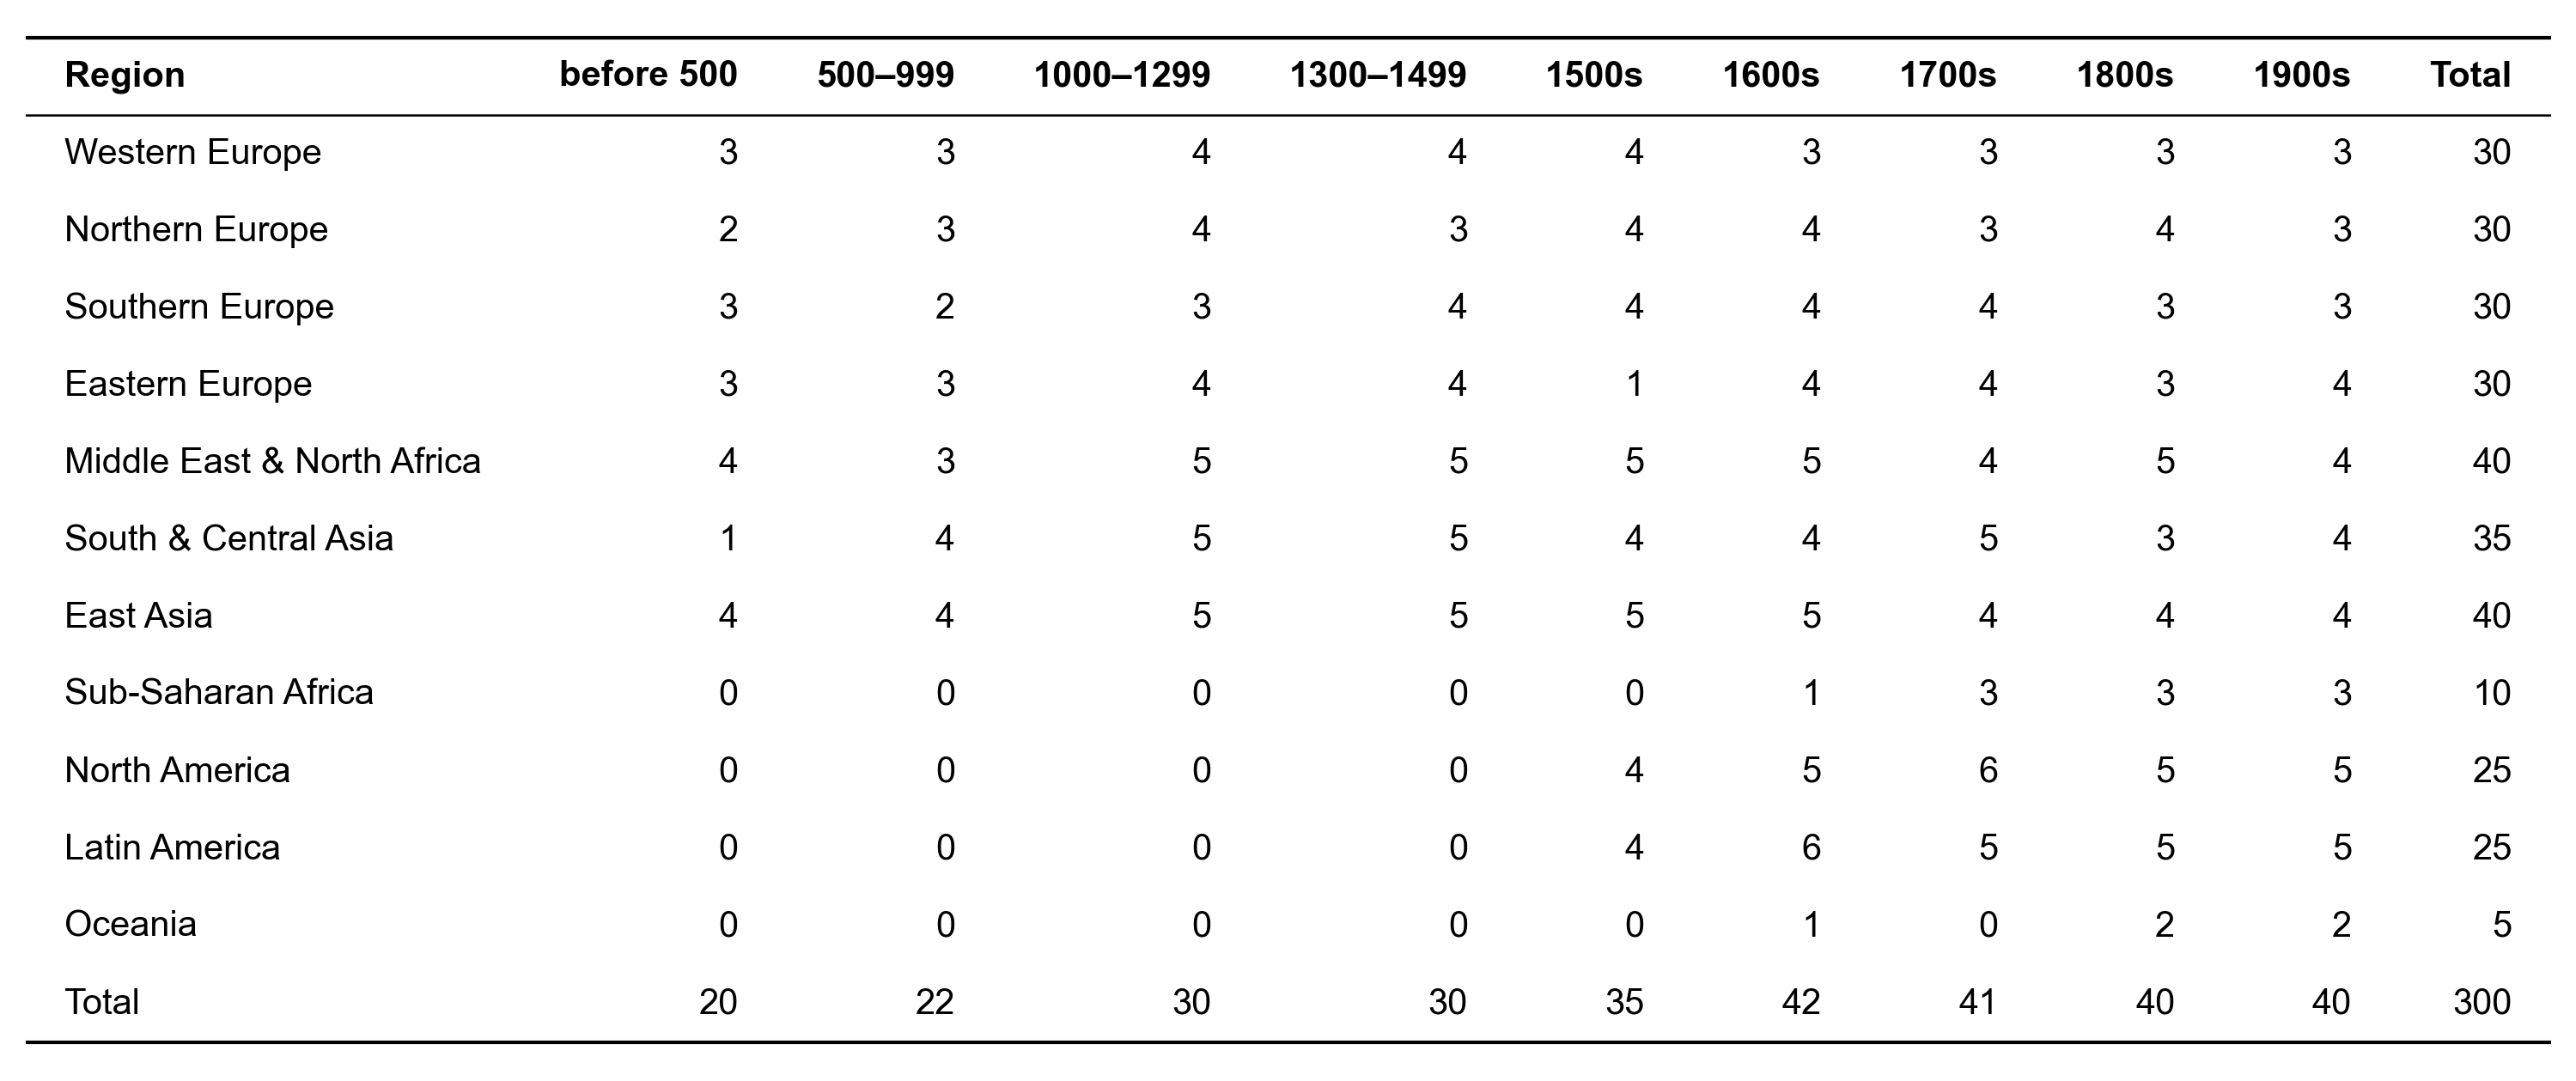

In [9]:
benchmark_region = (benchmark.pivot(on="period", index="region", values="qid", aggregate_function="len")
    .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order"))
    .sort("order").fill_null(0))
present = [label for label in labels if label in benchmark_region.columns]
benchmark_region = benchmark_region.select(pl.col("region").alias("Region"), *present).with_columns(Total=pl.sum_horizontal(*present))
totals = pl.DataFrame([{"Region": "Total", **{c: benchmark_region[c].sum() for c in benchmark_region.columns[1:]}}])
show_table(pl.concat([benchmark_region, totals], how="vertical_relaxed"), font_size=10)